# Excitation energies from the Riemannian Hessian

The **symplectic (Williamson) eigenvalues of the Riemannian Hessian** at a critical point on the
fixed-rank tensor-train manifold, following Grazioli, Hu & Cancès
([arXiv:2506.16420](https://arxiv.org/abs/2506.16420)). At full rank the ω must reproduce the exact
FCI gaps; below it they are fixed-rank estimates whose error is a property of the ansatz.

In [1]:
# Use the notebook environment (see notebooks/Project.toml) regardless of which kernel started us.
using Pkg
Pkg.activate(@__DIR__)

  Activating 

project at `~/Dropbox/Workplace/RustPackages/qntt/notebooks`


In [2]:
using QNTT, LinearAlgebra, Printf, Combinatorics, Plots
gr()
QNTT.init()

# Where the integral fixtures live, and a loader for the pyscf-exported `meta/h1/h2` format
# (used by the LiH and N2 fixtures that are not FCIDUMP files).
const ROOT = normpath(joinpath(@__DIR__, ".."))
fixture(parts...) = joinpath(ROOT, "testdata", parts...)

"""
Load a fixture directory: a keyed `meta.txt` plus the FCIDUMP its `dump_file` key names.

`e_ref` is *whatever reference the fixture was generated against*, and the meta says which by the
key it uses — `e_fci` where the determinant count allowed one, `e_ccsd_t` otherwise. It is never a
generic slot whose meaning varies per fixture (two fixtures used to record `e_ref == e_hf`, from a
skipped FCI silently falling back to the SCF energy).

These directories used to ship `h1.dat`/`h2.dat`: a dense positional dump with no write threshold,
which carried entries down to ~1e-22 where an FCIDUMP is written at 1e-15 — the same molecule with
materially different content (66% of `h2.dat` and 17.5% of the assembled operator at N₂/cc-pVDZ).
One format, so the question does not arise.
"""
function load_fixture(dir)
    meta = Dict{String,String}()
    for line in eachline(joinpath(dir, "meta.txt"))
        line = strip(line)
        (isempty(line) || startswith(line, "#")) && continue
        parts = split(line, limit = 2)
        length(parts) == 2 && (meta[parts[1]] = strip(parts[2]))
    end
    getf(k) = parse(Float64, meta[k])
    d      = parse(Int, meta["norb"])
    nelec  = parse(Int, meta["nelec"])
    ms2    = parse(Int, get(meta, "ms2", "0"))
    e_nuc  = getf("e_nuc")
    e_hf   = haskey(meta, "e_hf") ? getf("e_hf") : NaN
    refkey = findfirst(k -> haskey(meta, k), ["e_fci", "e_ccsd_t", "e_ccsd"])
    e_ref  = refkey === nothing ? NaN : getf(["e_fci", "e_ccsd_t", "e_ccsd"][refkey])

    ints = QNTT.read_fcidump(joinpath(dir, meta["dump_file"]))
    t, v = QNTT.onebody(ints), QNTT.twobody(ints)
    @assert size(t) == (d, d) "meta norb=$d disagrees with $(meta["dump_file"])"
    return (; t, v, d, nelec, ms2, e_nuc, e_hf, e_ref)
end

# --- the state cache ---------------------------------------------------------------------------
# The ground-state pipeline is deterministic and expensive (~2 minutes for water 6-31G at M = 64),
# while every downstream experiment repeats it verbatim. So: build once, save, and reuse. Cold on the first execution, warm in milliseconds
# thereafter.
#
# The cache is a local file, NOT an archival format: it records the build that wrote it and refuses
# anything else, and there is no migration path. If `load` ever complains, delete the file and let
# the cold path run again.
#
# It keys on the physical setup only (fixture, 2S, M and a tag). CHANGING A SOLVER KNOB DOES NOT
# INVALIDATE IT — delete `notebooks/cache/` by hand after editing the schedule below, or you will
# be reading a state built with the old one. The space is re-checked on load, so a change that
# alters the space is caught; one that only alters the path to the state is not.
const CACHE_DIR = joinpath(@__DIR__, "cache")
cache_file(tag) = joinpath(CACHE_DIR, tag * ".tt")

"""
    cached(T, L, tag, space, build) -> (x, :warm|:cold, seconds)

Return the cached state `tag`, or build it with `build()` and save it. The loaded state's space
must equal `space`, so a cache left over from a different physical setup is an error rather than a
silent wrong answer.
"""
function cached(::Type{T}, ::Type{L}, tag, space, build) where {T,L}
    path = cache_file(tag)
    if isfile(path)
        t = @elapsed x = QNTT.load(T, L, path)
        QNTT.space(x) == space ||
            error("cache $path holds $(QNTT.space(x)), but this run wants $space; delete it")
        return (x, :warm, t)
    end
    t = @elapsed x = build()
    mkpath(CACHE_DIR)
    QNTT.save(x, path)
    return (x, :cold, t)
end

report_cache(tag, how, t) = how === :warm ?
    @printf("cache HIT  %s — loaded in %.3f s (the pipeline below was skipped)\n", tag, t) :
    @printf("cache MISS %s — built in %.1f s and saved for next time\n", tag, t)


h4 = QNTT.read_fcidump(fixture("h4.FCIDUMP"))
space = QNTT.QnSpace(h4)
H = QNTT.Hamiltonian(space, h4)
@printf("%s, E_core = %.10f\n", string(space), QNTT.e0(h4))

QnSpace(d=4, Nup=2, Ndn=2), E_core = 2.2931012473


## The exact answer, first

`C(4,2)² = 36` determinants — small enough to diagonalize exactly. `tt_state` builds each as a
rank-1 train, `xthy(x, H, y)` contracts `⟨x, H·y⟩`.

In [3]:
d, nup, ndn = space.d, space.a, space.b
dets = [(u, v) for u in combinations(0:d-1, nup) for v in combinations(0:d-1, ndn)]
basis = [QNTT.tt_state([k in u for k in 0:d-1], [k in v for k in 0:d-1]) for (u, v) in dets]
n = length(basis)

Hmat = [QNTT.xthy(basis[i], H, basis[j]) for i in 1:n, j in 1:n]
@printf("%d determinants; ‖H − Hᵀ‖ = %.2e\n", n, norm(Hmat - Hmat'))

E = eigvals(Symmetric((Hmat + Hmat') / 2))
gaps = E[2:end] .- E[1]

@printf("\nFCI ground state      E₀ = %.12f Ha  (electronic)\n", E[1])
@printf("FCI excitation energies (Ha):\n")
for k in 1:8
    @printf("   E%d − E₀ = %.9f\n", k, gaps[k])
end

36 determinants; ‖H − Hᵀ‖ = 7.36e-16

FCI ground state      E₀ = -4.459488695955 Ha  (electronic)


FCI excitation energies (Ha):
   E1 − E₀ = 0.232630215


   E2 − E₀ = 0.446893306
   E3 − E₀ = 0.516729562
   E4 − E₀ = 0.543249422
   E5 − E₀ = 0.728696165
   E6 − E₀ = 0.834112091
   E7 − E₀ = 0.881564883
   E8 − E₀ = 0.951730873


## Linear response at full rank

Converge on a manifold large enough to be exact, then ask for the lowest symplectic eigenvalues.
`rpa` is matrix-free, a convenience over `rpa_signed`; `max_iter` counts `(A, B)` apply pairs.

In [4]:
x0 = QNTT.tt_randn(space, QNTT.uniform_ranks(space, 8); seed = 7)
λ, x = QNTT.als(H, x0; eps = 1e-12, max_iter = 200)

@printf("ground state: λ = %.12f  (FCI E₀ = %.12f, difference %.1e)\n", λ, E[1], λ - E[1])
@printf("manifold: max bond dimension %d\n", QNTT.max_bond_rank(x))

ω, info = QNTT.rpa(H, x; k = 6, tol = 1e-10, max_iter = 800)
@printf("\nRPA: %d Krylov vectors, %d Hessian applies, converged = %s\n",
        info.iterations, info.applies, info.converged)

ground state: λ = -4.459488695955  (FCI E₀ = -4.459488695955, difference -1.8e-15)
manifold: max bond dimension 16



RPA: 35 Krylov vectors, 35 Hessian applies, converged = true


In [5]:
@printf("%-4s %18s %18s %14s\n", "j", "ω_j (RPA)", "E_j − E₀ (FCI)", "difference")
for j in eachindex(ω)
    @printf("%-4d %18.12f %18.12f %14.2e\n", j, ω[j], gaps[j], ω[j] - gaps[j])
end

j             ω_j (RPA)     E_j − E₀ (FCI)     difference
1        0.232630215120     0.232630215120       5.00e-16


2        0.446893306004     0.446893306004       5.05e-15
3        0.516729562433     0.516729562433       3.44e-15
4        0.543249422254     0.543249422254      -1.11e-16
5        0.728696165382     0.728696165382       2.11e-15
6        0.834112091183     0.834112091183       2.33e-15


They agree to solver tolerance — the strongest available test of the whole Hessian machinery.

## The certified dense driver

`rpa_dense` assembles the whole tangent basis and runs Williamson directly: a small-system
reference rather than a production path.

In [6]:
ωd = QNTT.rpa_dense(H, x)

@printf("dense driver returned %d values; matrix-free returned %d\n", length(ωd), length(ω))
@printf("%-4s %18s %18s %14s\n", "j", "matrix-free", "dense", "difference")
for j in eachindex(ω)
    @printf("%-4d %18.12f %18.12f %14.2e\n", j, ω[j], ωd[j], ω[j] - ωd[j])
end

dense driver returned 35 values; matrix-free returned 6
j           matrix-free              dense     difference


1        0.232630215120     0.232630215120       1.39e-15
2        0.446893306004     0.446893306004       1.55e-15
3        0.516729562433     0.516729562433       1.22e-15
4        0.543249422254     0.543249422254      -3.66e-15
5        0.728696165382     0.728696165382      -5.55e-16
6        0.834112091183     0.834112091183       1.44e-15


Multiplicities are **resolved**: `k` counts physical values with multiplicity. Never de-duplicate
the output — a repeat is a degeneracy to be checked, never deleted.

## What happens below full rank

The ω become approximations — an ansatz bias, not noise.

In [7]:
ranks = [1, 2, 3, 4, 6]
rows = map(ranks) do r
    x0 = QNTT.tt_randn(space, QNTT.uniform_ranks(space, r); seed = 7)
    λr, xr = QNTT.als(H, x0; eps = 1e-12, max_iter = 300)
    # Below some rank the reference is poor enough that its RPA spectrum is no longer real (an
    # imaginary or complex mode, a de-excitation), and there is no ω to report. `rpa` throws rather
    # than returning numbers (`rpa_signed` returns the signed spectrum as data) — catch that and
    # record it, because it is a real answer about the state, not a solver failure.
    ωr = try
        first(QNTT.rpa(H, xr; k = 4, tol = 1e-10, max_iter = 800))
    catch e
        e isa QNTTError || rethrow()
        nothing
    end
    (; r, λ = λr, bond = QNTT.max_bond_rank(xr), ω = ωr)
end

@printf("%-5s %-6s %16s   %s\n", "rank", "bond", "λ − E₀", "ω₁ … ω₄")
for row in rows
    @printf("%-5d %-6d %16.2e   %s\n", row.r, row.bond, row.λ - E[1],
            row.ω === nothing ? "— no PD metric, so no spectrum" :
            join([@sprintf("%.6f", w) for w in row.ω], "  "))
end

rank  bond             λ − E₀   ω₁ … ω₄
1     9              2.95e-02   — no PD metric, so no spectrum


2     14             2.60e-03   0.242030  0.443815  0.540339  0.610289
3     15             1.00e-03   0.194031  0.445276  0.486661  0.520919
4     16            -1.78e-15   0.232630  0.446893  0.516730  0.543249
6     16            -1.78e-15   0.232630  0.446893  0.516730  0.543249


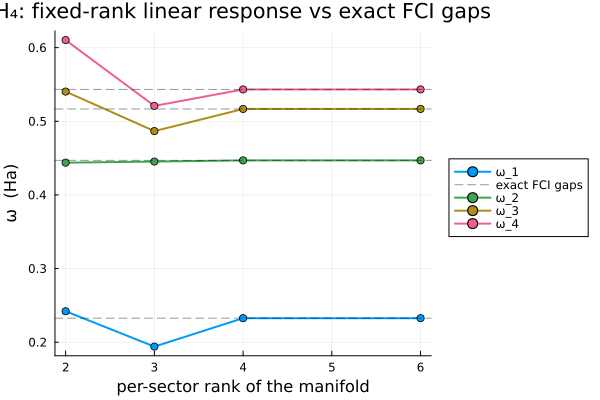

In [8]:
ok = [row for row in rows if row.ω !== nothing]      # ranks that HAVE a symplectic spectrum
p = plot(; xlabel = "per-sector rank of the manifold", ylabel = "ω  (Ha)",
         title = "H₄: fixed-rank linear response vs exact FCI gaps",
         legend = :outerright)
for j in 1:4
    plot!(p, [row.r for row in ok], [row.ω[j] for row in ok];
          marker = :circle, lw = 2, label = "ω_$j")
    hline!(p, [gaps[j]]; ls = :dash, lc = :black, alpha = 0.4,
           label = j == 1 ? "exact FCI gaps" : "")
end
p

## Caveats worth carrying

- The ω are **fixed-rank estimates**; quote the rank with the number.
- `x` must be a genuine **minimizer** — at a saddle `rpa` throws (no real ω); `rpa_signed` returns
  the signed spectrum there.
- Fixed-rank TT is nonlinear, so critical points need not be excited states.

---

# Part II — a real system, and what it takes to trust the answer

Water 6-31G at `M = 64`, the ground state notebook 02 builds and caches. The order is fixed:

`pd_probe` on both blocks of the Hessian → a **stability verdict** → `rpa` for the excitation
energies → a comparison with full-space FCI.

`rpa` publishes ω only at a stable point; at an unstable one it throws and `rpa_signed` returns the
signed spectrum as data. The probes come first because a verdict is only as good as the budget behind
it, and that is a knob you set.

### Knobs to play with

| knob | default | controls |
|---|---|---|
| `PROBE_BUDGET` | 600 | `pd_probe` Davidson iterations; at 200 both parts are still `:inconclusive` |
| `RPA_K` | 4 | physical ω returned, with multiplicity |
| `RPA_TOL` | 1e-4 | 3–4 digits, the target at this ansatz |
| `RPA_MAX_ITER` | 4000 | `(A, B)` apply pairs |

In [9]:
# The ground state is the expensive part, and notebook 02 already built and cached it. This
# reloads that exact file; run 02 first if it is absent.
const FIXTURE = "h2o_631g"
const TWO_S   = 0
const M       = 64

fx = load_fixture(fixture(FIXTURE))
space_w = QNTT.Su2Space(fx.d, fx.nelec, TWO_S)
H_w = QNTT.Hamiltonian(space_w, fx.t, fx.v)

const GS_TAG = @sprintf("%s_2S%d_M%d_gs", FIXTURE, TWO_S, M)
if !isfile(cache_file(GS_TAG))
    error("no cached ground state at $(cache_file(GS_TAG)) — run notebook 02 first; " *
          "its final section builds and caches exactly this state.")
end
x_w, how, t_load = cached(Float64, QNTT.SU2, GS_TAG, space_w, () -> error("unreachable"))
report_cache(GS_TAG, how, t_load)

λ_w = QNTT.rayleigh_quotient(H_w, x_w)
E_w = λ_w + fx.e_nuc
@printf("\nE        = %.9f Ha   (%.2f%% of the correlation energy)\n",
        E_w, 100 * (fx.e_hf - E_w) / (fx.e_hf - fx.e_ref))
@printf("‖grad‖   = %.3e   %s\n", QNTT.grad_norm(H_w, x_w),
        QNTT.grad_norm(H_w, x_w) < 1e-9 ? "(critical)" : "(NOT critical — the probes below are then not about a minimizer)")
@printf("σ_min    = %.3e\n", QNTT.sigma_min(x_w))
@printf("bond dims = %s\n", string([sum(g) for g in QNTT.ranks(x_w)]))

cache HIT  h2o_631g_2S0_M64_gs — loaded in 0.000 s (the pipeline below was skipped)

E        = -76.119211536 Ha   (98.53% of the correlation energy)


‖grad‖   = 9.219e-11   (critical)
σ_min    = 6.217e-04


bond dims = [1, 2, 4, 11, 29, 66, 88, 79, 66, 46, 18, 7, 3, 1]


## The stability gate

`pd_probe` returns a Rayleigh quotient of the Hessian part, so a negative answer is a *proof* (a
variational upper bound on `λ_min`) and a non-negative one is evidence measured by its residual.

- **`:rr` = `A + B`**, the energy Hessian. Indefinite ⇒ the ground state is a *saddle*.
- **`:ii` = `A − B`**, imaginary-direction curvature. Indefinite ⇒ a *physical* instability no real
  optimizer ever looks at: the energy drops along a complex direction.

Both must be positive definite for real ω to exist.

In [10]:
const PROBE_BUDGET = 600     # Davidson iterations ≈ Hessian applies
const PROBE_SEED   = 1234    # fixes the random starting tangent direction

for part in (:rr, :ii)
    t = @elapsed r = QNTT.pd_probe(H_w, x_w; part = part, budget = PROBE_BUDGET, seed = PROBE_SEED)
    @printf("pd_probe(:%s)  %-16s λ = %+.6e   residual = %-10s margin = %+.2e   %3d applies  %5.1f s\n",
            part, r.verdict, r.lambda,
            isnan(r.residual) ? "n/a" : @sprintf("%.1e", r.residual),
            r.lambda - r.residual, r.applies, t)
end

pd_probe(:rr)  likely_pd        λ = +1.629278e-02   residual = 1.8e-03    margin = +1.45e-02   278 applies   47.0 s
pd_probe(:ii)  likely_pd        λ = +1.713768e-02   residual = 3.9e-04    margin = +1.67e-02   272 applies   50.3 s


Read each verdict as a pair: `λ_min` beside its residual. The **margin** `λ_min − residual` is the
number that decides whether `λ_min > 0` is real; a `:likely_pd` whose residual reaches `λ_min` says
nothing.

### The verdict depends on the budget

The same probe at a third of the budget, and at another seed:

In [11]:
for (seed, budget) in ((PROBE_SEED, 200), (99, 200), (PROBE_SEED, PROBE_BUDGET))
    t = @elapsed r = QNTT.pd_probe(H_w, x_w; part = :ii, budget = budget, seed = seed)
    @printf("  seed %5d, budget %3d:  %-14s λ = %+.6e   residual = %.1e   %5.1f s\n",
            seed, budget, r.verdict, r.lambda, r.residual, t)
end

  seed  1234, budget 200:  inconclusive   λ = +1.770118e-02   residual = 9.2e-03    32.5 s
  seed    99, budget 200:  inconclusive   λ = +1.768265e-02   residual = 6.7e-03    30.4 s


  seed  1234, budget 600:  likely_pd      λ = +1.713768e-02   residual = 3.9e-04    48.1 s


At 200 iterations the bound has settled but the residual has not: `:inconclusive` is *not* a PD
claim, it is the probe declining to make one. Quote a verdict with its budget.

### Nothing to complexify along

At a state where `:ii` *is* indefinite, the proven negative direction `w` is the way out:
`complex_seed` steps to `retract(x, i·ε·ŵ)`, a complex polish finds the lower complex critical
point, and the RPA is done there. Here the gate says there is no such direction, and
`complex_seed` refuses to invent one:

In [12]:
try
    QNTT.complex_seed(H_w, x_w; eps = 1e-2, budget = PROBE_BUDGET, seed = PROBE_SEED)
    println("complex_seed returned a seed: the probe found a negative H^ii direction after all")
catch e
    e isa QNTTError || rethrow()
    println(sprint(showerror, e))
end

QNTTError(5): complex seed: the H^ii probe found no negative direction (LikelyPd, λ_min = 1.713768e-2, residual = 3.891e-4). There is nothing to complexify along — this state is stable against complex perturbations at this rank.


The refusal is the answer: the real ground state is stable against complex perturbations at this
rank, so the linear response is computed at the real state itself.

## Excitation energies

`tol ≈ 1e-4`: the model error is several percent, so more digits refine a number already wrong in the
second.

In [13]:
const RPA_TOL      = 1e-4    # 3-4 digits: the physically meaningful target at this ansatz
const RPA_K        = 4       # physical values, with multiplicity
const RPA_MAX_ITER = 4000    # budget in (A, B) apply pairs (pair-equivalents)

t = @elapsed ω, info = QNTT.rpa(H_w, x_w; k = RPA_K, tol = RPA_TOL,
                                max_iter = RPA_MAX_ITER, seed = 1)
@printf("rpa: %d values, converged = %s, %d basis vectors, %d (A, B) apply pairs, %.1f s\n",
        length(ω), info.converged, info.iterations, info.applies, t)
for (j, w) in enumerate(ω)
    @printf("  ω[%d] = %.6f Ha\n", j, w)
end
info.converged ||
    println("\nNOT at tolerance in $RPA_MAX_ITER apply pairs. The lowest values settle first, " *
            "so ω[1] and ω[2] are trustworthy well before the upper ones; raise RPA_MAX_ITER to " *
            "tighten the rest. This is a budget statement, not a failure.")

rpa: 4 values, converged = true, 550 basis vectors, 550 (A, B) apply pairs, 225.7 s
  ω[1] = 0.302809 Ha


  ω[2] = 0.305408 Ha
  ω[3] = 0.358487 Ha
  ω[4] = 0.392347 Ha


true

In [14]:
# Full-space FCI singlet gaps for this exact system, from the CASSCF-paper reference set. No JSON
# dependency: pull the one array we need out of the `6-31g` block textually, and assert on what
# came back rather than trusting the scrape.
refs = read(fixture("casscf_paper_references.json"), String)
blk = refs[findfirst("\"6-31g\"", refs)[1]:end]
span = blk[findfirst("\"fci_gaps\"", blk)[1]:end]
span = span[findfirst("[", span)[1]:findfirst("]", span)[1]]
fci_gaps = [parse(Float64, m.match) for m in eachmatch(r"-?\d+\.\d+(?:[eE][-+]?\d+)?", span)]
length(fci_gaps) == 2 || error("expected 2 FCI gaps, scraped $(length(fci_gaps)): $fci_gaps")
@printf("full-space FCI singlet gaps: %s Ha  (%d determinants)\n",
        join([@sprintf("%.6f", g) for g in fci_gaps], ", "), 1656369)

# Pair each FCI gap with its NEAREST ω, not by index. The reference file carries three FCI roots,
# hence two gaps; the fixed-rank spectrum has its own density of states and need not line up
# one-for-one, so an index-by-index table would be comparing whatever happened to be in slot 2.
@printf("\n%-16s %14s %10s %12s\n", "FCI (full space)", "nearest ω", "index", "error")
for g in fci_gaps
    j = argmin(abs.(ω .- g))
    @printf("%-16.6f %14.6f %10d %11.2f%%\n", g, ω[j], j, 100 * (ω[j] - g) / g)
end
unmatched = [j for j in eachindex(ω) if !(j in [argmin(abs.(ω .- g)) for g in fci_gaps])]
isempty(unmatched) ||
    @printf("\nTT values with no counterpart among the reference's roots: %s\n",
            join([@sprintf("ω[%d] = %.6f", j, ω[j]) for j in unmatched], ", "))

full-space FCI singlet gaps: 0.266970, 0.294410 Ha  (1656369 determinants)

FCI (full space)      nearest ω      index        error


0.266970               0.302809          1       13.42%
0.294410               0.302809          1        2.85%



TT values with no counterpart among the reference's roots: ω[2] = 0.305408, ω[3] = 0.358487, ω[4] = 0.392347


Every ω sits **above** both FCI gaps, by several percent to over ten, against a 1.66-million-determinant
full space at pooled bond dimension 64. Pairing by nearest value can send both gaps to the same `ω`
— the table prints the index so that is visible rather than hidden. Which fixed-rank mode
corresponds to which FCI state is not settled by energies alone; the ω are fixed-rank estimates,
quoted with the rank.